In [63]:
import pandas as pd
import os

# Load files
desktop_path = r"C:\Users\stratklar\Documents\Markus\ASA\Indien\mobile_data\sample2"
imu_path = os.path.join(desktop_path, "Accelerometer.csv")
synchronization_path = os.path.join(desktop_path, "synchronization2.csv")
imu_df = pd.read_csv(imu_path)
sync_df = pd.read_csv(synchronization_path)

print("IMU dataset:")
print(imu_df.shape)
print(imu_df.columns.tolist())

print("\nSynchronization dataset:")
print(sync_df.shape)
print(sync_df.columns.tolist())

IMU dataset:
(6099, 5)
['time', 'seconds_elapsed', 'z', 'y', 'x']

Synchronization dataset:
(1216, 33)
['timestamp', 'timestamp_seconds', 'accelerometer_time', 'accelerometer_seconds_elapsed', 'accelerometer_z', 'accelerometer_y', 'accelerometer_x', 'location_time', 'location_seconds_elapsed', 'location_altitude', 'location_speedAccuracy', 'location_bearingAccuracy', 'location_latitude', 'location_altitudeAboveMeanSeaLevel', 'location_bearing', 'location_horizontalAccuracy', 'location_verticalAccuracy', 'location_longitude', 'location_speed', 'gyroscope_time', 'gyroscope_seconds_elapsed', 'gyroscope_z', 'gyroscope_y', 'gyroscope_x', 'orientation_time', 'orientation_seconds_elapsed', 'orientation_yaw', 'orientation_qx', 'orientation_qz', 'orientation_roll', 'orientation_qw', 'orientation_qy', 'orientation_pitch']


In [47]:
imu_columns = [
    "orientation_z",
    "orientation_w",
    "angular_velocity_x",
    "angular_velocity_y",
    "angular_velocity_z",
    "linear_acceleration_x",
    "linear_acceleration_y",
    "linear_acceleration_z"
]

required_imu_columns = [
    "timestamp_seconds"
] + imu_columns

# Check columns
missing_imu = [
    col for col in required_imu_columns
    if col not in imu_df.columns
]

if missing_imu:
    print("Missing columns in imu12.csv:")
    print(missing_imu)
else:
    print("All required IMU columns are present.")

Missing columns in imu12.csv:
['timestamp_seconds', 'orientation_z', 'orientation_w', 'angular_velocity_x', 'angular_velocity_y', 'angular_velocity_z', 'linear_acceleration_x', 'linear_acceleration_y', 'linear_acceleration_z']


In [ ]:
if "imu_timestamp_ns" not in sync_df.columns:
    raise ValueError(
        "imu_timestamp_ns column not found in synchronization12.csv"
    )

print("Synchronization timestamp column found.")

In [ ]:
# Keep only the required IMU data
imu_selected = imu_df[required_imu_columns].copy()

# Rename timestamp so both datasets use the same name
imu_selected = imu_selected.rename(
    columns={"timestamp_ns": "imu_timestamp_ns"}
)

# Match synchronization timestamps with IMU timestamps
merged_df = sync_df.merge(
    imu_selected,
    on="imu_timestamp_ns",
    how="left"
)

print("Merged dataset shape:", merged_df.shape)

display(merged_df.head())

In [ ]:
for col in imu_columns:
    missing_count = merged_df[col].isna().sum()

    print(
        f"{col}: "
        f"{len(merged_df) - missing_count} matched, "
        f"{missing_count} missing"
    )

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

imu_columns = [
    "orientation_z",
    "orientation_w",
    "orientation_y",
    "orientation_x",
    "angular_velocity_x",
    "angular_velocity_y",
    "angular_velocity_z",
    "linear_acceleration_x",
    "linear_acceleration_y",
    "linear_acceleration_z",
    "altitude",
    "latitude",
    "longitude",
    "speed"
]

# Make sure the columns are numeric
for col in imu_columns:
    merged_df[col] = pd.to_numeric(
        merged_df[col],
        errors="coerce"
    )

# Create reading number
merged_df = merged_df.reset_index(drop=True)
merged_df["reading"] = np.arange(len(merged_df))

print("Number of readings:", len(merged_df))

In [64]:
import numpy as np

DRAMATIC_PERCENTILE = 99.8

drastic_points = {}

sync_df["time"] = (
    sync_df["timestamp_seconds"] - sync_df["timestamp_seconds"].min()
)

for col in sync_df.columns:

    # Difference between consecutive readings
    change = sync_df[col].diff().abs()

    # Remove NaN
    valid_change = change.dropna()

    # Calculate automatic threshold
    threshold = np.percentile(
        valid_change,
        DRAMATIC_PERCENTILE
    )

    # Find drastic changes
    mask = change > threshold

    drastic_points[col] = {
        "change": change,
        "threshold": threshold,
        "mask": mask
    }

    print("=" * 70)
    print(col)
    print("Threshold:", threshold)
    print("Drastic changes:", mask.sum())

timestamp
Threshold: 812776300.0
Drastic changes: 1
timestamp_seconds
Threshold: 0.8127763271331787
Drastic changes: 1
accelerometer_time
Threshold: 812776192.0
Drastic changes: 1
accelerometer_seconds_elapsed
Threshold: 0.8127762626953126
Drastic changes: 3
accelerometer_z
Threshold: 7.7055389223240285
Drastic changes: 3
accelerometer_y
Threshold: 2.097658350712715
Drastic changes: 3
accelerometer_x
Threshold: 1.5968323163267997
Drastic changes: 3
location_time
Threshold: 1000002232.32
Drastic changes: 3
location_seconds_elapsed
Threshold: 1.0000024082031225
Drastic changes: 3
location_altitude
Threshold: 0.5783466375432885
Drastic changes: 3
location_speedAccuracy
Threshold: 0.1261386678989217
Drastic changes: 3
location_bearingAccuracy
Threshold: 11.424612978374078
Drastic changes: 3
location_latitude
Threshold: 9.680794342283836e-05
Drastic changes: 3
location_altitudeAboveMeanSeaLevel
Threshold: 0.5783466375432885
Drastic changes: 3
location_bearing
Threshold: 1.4575114135741478
D

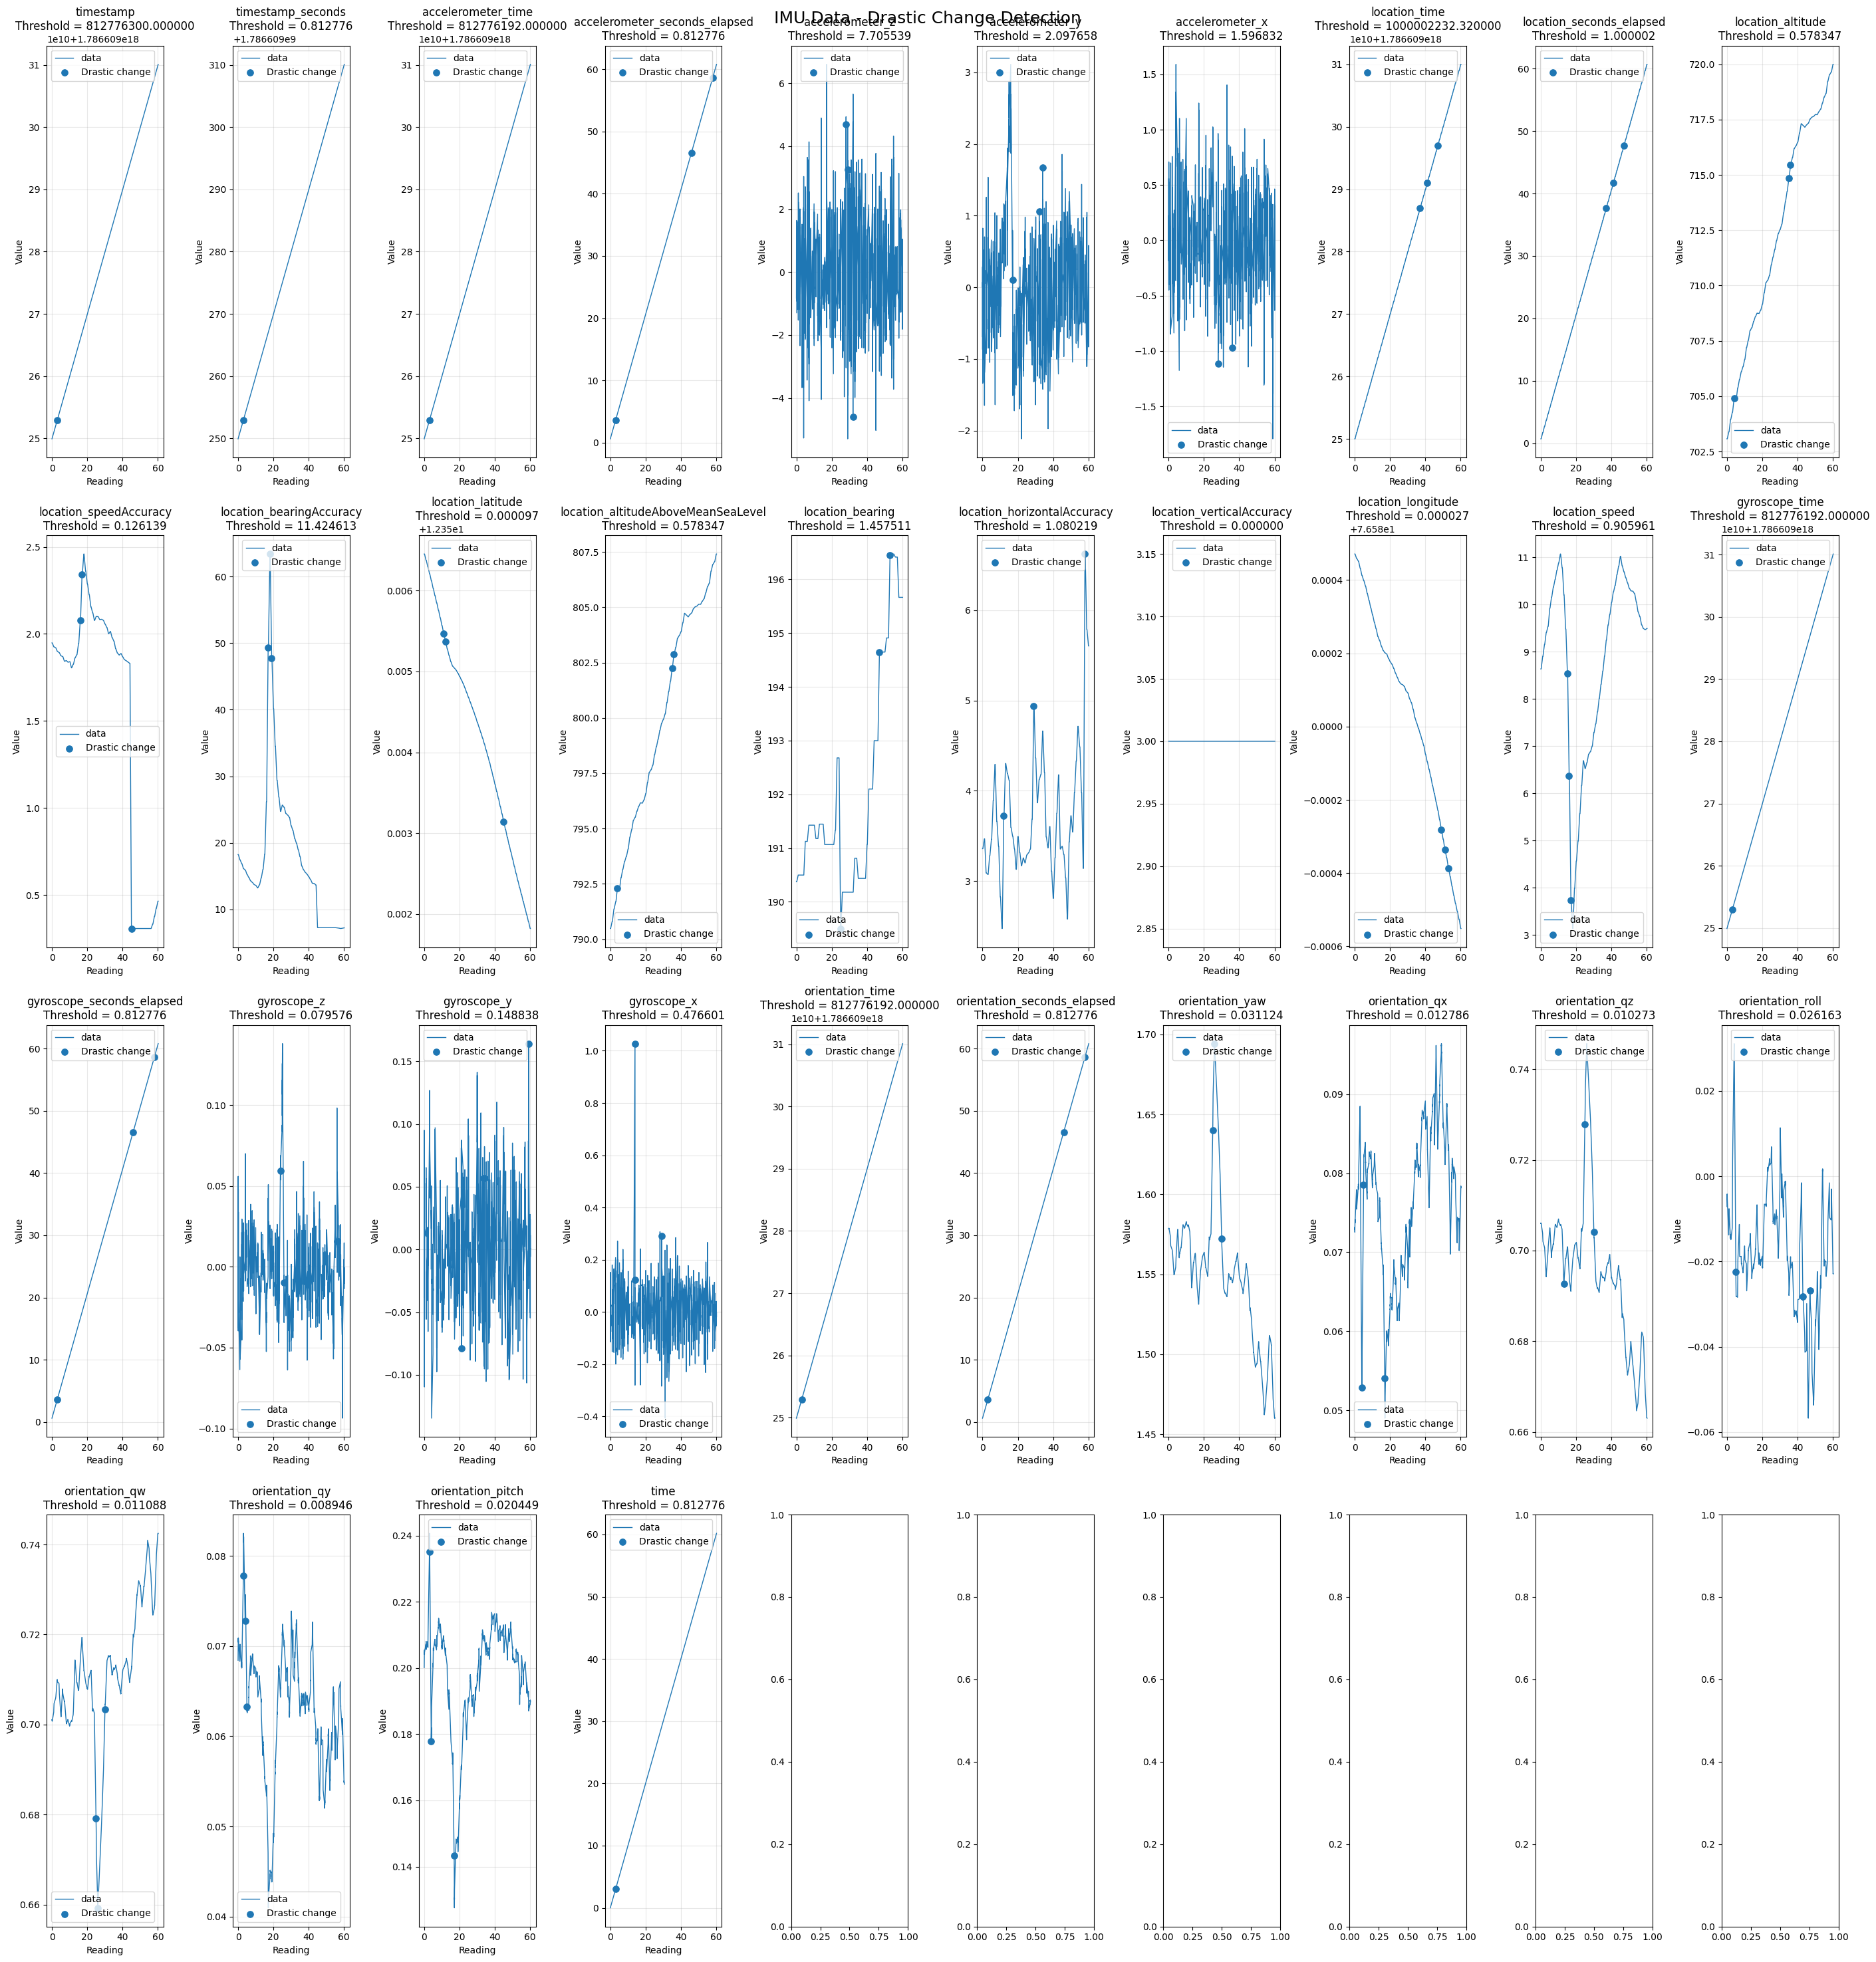

In [65]:
import matplotlib.pyplot as plt

sync_df["time"] = (
    sync_df["timestamp_seconds"] - sync_df["timestamp_seconds"].min()
)

fig, axes = plt.subplots(
    4,
    10,
    figsize=(28, 30)
)

axes = axes.flatten()

for i, col in enumerate(sync_df.columns):

    ax = axes[i]

    # Original IMU data
    ax.plot(
        sync_df["time"],
        sync_df[col],
        linewidth=1,
        label="data"
    )

    # Drastic change locations
    mask = drastic_points[col]["mask"]

    ax.scatter(
        sync_df.loc[mask, "time"],
        sync_df.loc[mask, col],
        s=45,
        label="Drastic change",
        zorder=5
    )

    # Title
    threshold = drastic_points[col]["threshold"]

    ax.set_title(
        f"{col}\nThreshold = {threshold:.6f}"
    )

    ax.set_xlabel("Reading")
    ax.set_ylabel("Value")

    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "IMU Data - Drastic Change Detection",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [66]:
import os

all_changes = []

for col in sync_df.columns:
    mask = drastic_points[col]["mask"]
    change = drastic_points[col]["change"]
    threshold = drastic_points[col]["threshold"]

    for index in sync_df.index[mask]:
        all_changes.append({
            #"common_timestamp_ns": sync_df.loc[index, "common_timestamp_ns"],
            "time": sync_df.loc[index, "time"],
            #"color_image_timestamp_ns": merged_df.loc[index, "common_timestamp_ns"],
            #"imu_timestamp_ns": merged_df.loc[index, "imu_timestamp_ns"],
            #"reading": merged_df.loc[index, "reading"],
            "column": col,
            "value": sync_df.loc[index, col],
            "change": change.loc[index],
            "threshold": threshold
        })

drastic_changes_df = pd.DataFrame(all_changes)

drastic_changes_df = drastic_changes_df.sort_values(
    by=["time", "column"]
).reset_index(drop=True)
drastic_changes_df.to_csv(os.path.join(desktop_path, "drastic_changes.csv"), index = False)
display(drastic_changes_df)

,time,column,value,change,threshold
0,3.000249,accelerometer_seconds_elapsed,3.611616e+00,8.127771e-01,8.127763e-01
1,3.000249,accelerometer_time,1.786609e+18,8.127770e+08,8.127762e+08
2,3.000249,gyroscope_seconds_elapsed,3.611616e+00,8.127771e-01,8.127763e-01
3,3.000249,gyroscope_time,1.786609e+18,8.127770e+08,8.127762e+08
4,3.000249,orientation_pitch,2.351874e-01,2.515554e-02,2.044851e-02
...,...,...,...,...,...
82,57.998050,accelerometer_seconds_elapsed,5.860942e+01,8.127764e-01,8.127763e-01
83,57.998050,gyroscope_seconds_elapsed,5.860942e+01,8.127764e-01,8.127763e-01
84,57.998050,location_horizontalAccuracy,6.624455e+00,3.485145e+00,1.080219e+00
85,57.998050,orientation_seconds_elapsed,5.860942e+01,8.127764e-01,8.127763e-01


In [67]:
summary = (
    drastic_changes_df
    .groupby("column")
    .agg(
        Min_Change=("change", "min"),
        Max_Change=("change", "max"),
        Avg_Change=("change", "mean"),
        Threshold=("threshold", "first"),
        Drastic_Change_Count=("change", "count")
    )
    .reset_index()
)

display(summary)

,column,Min_Change,Max_Change,Avg_Change,Threshold,Drastic_Change_Count
0,accelerometer_seconds_elapsed,8.127764e-01,8.127771e-01,8.127766e-01,8.127763e-01,3
1,accelerometer_time,8.127770e+08,8.127770e+08,8.127770e+08,8.127762e+08,1
2,accelerometer_x,1.612181e+00,1.732281e+00,1.659496e+00,1.596832e+00,3
3,accelerometer_y,2.137662e+00,2.821998e+00,2.450766e+00,2.097658e+00,3
4,accelerometer_z,7.738400e+00,8.548667e+00,8.207835e+00,7.705539e+00,3
5,gyroscope_seconds_elapsed,8.127764e-01,8.127771e-01,8.127766e-01,8.127763e-01,3
6,gyroscope_time,8.127770e+08,8.127770e+08,8.127770e+08,8.127762e+08,1
7,gyroscope_x,4.863805e-01,1.054048e+00,8.150209e-01,4.766007e-01,3
8,gyroscope_y,1.522377e-01,1.720868e-01,1.611088e-01,1.488380e-01,3
9,gyroscope_z,8.268716e-02,1.275621e-01,1.005140e-01,7.957598e-02,3


In [68]:
import numpy as np

# Convert timestamp difference from nanoseconds to seconds
sync_df["dt"] = sync_df["time"].diff()

# Replace the first NaN value
sync_df["dt"] = sync_df["dt"].fillna(0)

# Initialize velocity
vx = 0.0
vy = 0.0
vz = 0.0

velocities = []

for _, row in sync_df.iterrows():

    dt = row["dt"]

    vx += row["accelerometer_x"] * dt
    vy += row["accelerometer_y"] * dt
    vz += row["accelerometer_z"] * dt

    # Calculate total speed
    speed = np.sqrt(vx**2 + vy**2 + vz**2)

    velocities.append(speed)

# Add speed columns
sync_df["speed_mps"] = velocities

# Convert m/s to km/h
sync_df["speed_kmph"] = sync_df["speed_mps"] * 3.6

In [69]:
print(sync_df[["time", "speed_mps", "speed_kmph"]])

           time  speed_mps  speed_kmph
0      0.000000   0.000000    0.000000
1      0.010034   0.003865    0.013914
2      0.020068   0.002262    0.008144
3      0.030103   0.012304    0.044296
4      0.040137   0.021200    0.076320
...         ...        ...         ...
1211  60.145381  10.578566   38.082838
1212  60.155415  10.575984   38.073543
1213  60.165450  10.575936   38.073370
1214  60.175484  10.568367   38.046120
1215  60.185518  10.561364   38.020910

[1216 rows x 3 columns]


In [70]:
display(sync_df.head())

,timestamp,timestamp_seconds,accelerometer_time,accelerometer_seconds_elapsed,accelerometer_z,accelerometer_y,accelerometer_x,location_time,location_seconds_elapsed,location_altitude,...,orientation_qx,orientation_qz,orientation_roll,orientation_qw,orientation_qy,orientation_pitch,time,dt,speed_mps,speed_kmph
0,1786609249908367400,1.786609e+09,1.786609e+18,0.611367,-0.826565,-0.689101,0.222528,1.786609e+18,0.703027,703.071156,...,0.072877,0.706071,-0.007117,0.701050,0.068424,0.200138,0.000000,0.000000,0.000000,0.000000
1,1786609249918401500,1.786609e+09,1.786609e+18,0.621402,0.257100,0.284623,0.035248,1.786609e+18,0.703027,703.071156,...,0.072991,0.706040,-0.006969,0.701048,0.068640,0.200609,0.010034,0.010034,0.003865,0.013914
2,1786609249928435200,1.786609e+09,1.786609e+18,0.631435,-0.407860,-0.357217,-0.186411,1.786609e+18,0.703027,703.071156,...,0.073168,0.706010,-0.006638,0.701020,0.069050,0.201445,0.020068,0.010033,0.002262,0.008144
3,1786609249938470400,1.786609e+09,1.786609e+18,0.641470,0.916393,-0.868322,-0.027270,1.786609e+18,0.703027,703.071156,...,0.072965,0.706029,-0.006257,0.701015,0.069114,0.201248,0.030103,0.010035,0.012304,0.044296
4,1786609249948504300,1.786609e+09,1.786609e+18,0.651504,1.152854,0.071880,0.012545,1.786609e+18,0.703027,703.071156,...,0.072704,0.705991,-0.005728,0.701072,0.069211,0.201018,0.040137,0.010034,0.021200,0.076320


In [61]:
all_changes = []

for col in imu_columns:
    mask = drastic_points[col]["mask"]
    change = drastic_points[col]["change"]
    threshold = drastic_points[col]["threshold"]

    for index in merged_df.index[mask]:
        all_changes.append({
            "common_timestamp_ns": merged_df.loc[index, "common_timestamp_ns"],
            "color_image_timestamp_ns": merged_df.loc[index, "common_timestamp_ns"],
            "imu_timestamp_ns": merged_df.loc[index, "imu_timestamp_ns"],
            "reading": merged_df.loc[index, "reading"],
            "column": col,
            "value": merged_df.loc[index, col],
            "change": change.loc[index],
            "threshold": threshold,
            "speed_kmph": merged_df.loc[index, "speed_kmph"],
        })

drastic_changes_df = pd.DataFrame(all_changes)

drastic_changes_df = drastic_changes_df.sort_values(
    by=["reading", "column"]
).reset_index(drop=True)

display(drastic_changes_df)

KeyError: 'orientation_z'

In [ ]:
imu_timestamp_ns

In [71]:
import numpy as np
import pandas as pd

# ============================================================
# CREATE A NEW DATAFRAME
# Keep original merged_df unchanged
# ============================================================

mergedsp_df = sync_df.copy()


# ============================================================
# CONFIGURATION
# ============================================================

TIMESTAMP_COL = "time"

AX_COL = "accelerometer_x"
AY_COL = "accelerometer_y"
AZ_COL = "accelerometer_z"

BIAS_SAMPLES = 50
ACCEL_THRESHOLD = 0.05
MAX_DT = 0.1


# ============================================================
# SORT BY TIMESTAMP
# ============================================================

mergedsp_df = mergedsp_df.sort_values(
    TIMESTAMP_COL
).reset_index(drop=True)

# ============================================================
# CALCULATE TIME DIFFERENCE
# Nanoseconds → seconds
# ============================================================

mergedsp_df["dt"] = (
    mergedsp_df[TIMESTAMP_COL].diff() / 1e9
)

mergedsp_df["dt"] = mergedsp_df["dt"].fillna(0)

# Remove invalid negative dt
mergedsp_df.loc[
    mergedsp_df["dt"] < 0,
    "dt"
] = 0

# Prevent huge jumps caused by timestamp gaps
mergedsp_df["dt"] = mergedsp_df["dt"].clip(
    lower=0,
    upper=MAX_DT
)

# ============================================================
# GET ONLY VALID IMU ACCELERATION
# ============================================================

imu_mask = mergedsp_df[
    [
        AX_COL,
        AY_COL,
        AZ_COL
    ]
].notna().all(axis=1)


# ============================================================
# ESTIMATE INITIAL ACCELERATION BIAS
# ============================================================

valid_imu = mergedsp_df.loc[
    imu_mask,
    [
        AX_COL,
        AY_COL,
        AZ_COL
    ]
]

bias_count = min(
    BIAS_SAMPLES,
    len(valid_imu)
)

bias_x = valid_imu[AX_COL].iloc[:bias_count].mean()
bias_y = valid_imu[AY_COL].iloc[:bias_count].mean()
bias_z = valid_imu[AZ_COL].iloc[:bias_count].mean()


print("IMU Bias:")
print("X:", bias_x)
print("Y:", bias_y)
print("Z:", bias_z)


# ============================================================
# CREATE ACCELERATION COLUMNS
# ============================================================

#mergedsp_df["accelerometer_x"] = np.nan
#mergedsp_df["accelerometer_y"] = np.nan
#mergedsp_df["accelerometer_z"] = np.nan

mergedsp_df.loc[imu_mask, "accelerometer_x"] = (
    mergedsp_df.loc[imu_mask, AX_COL] - bias_x
)

# ============================================================
# REMOVE SMALL ACCELERATION NOISE
# ============================================================

for col in ["accelerometer_x", "accelerometer_y", "accelerometer_z"]:

    mergedsp_df.loc[
        mergedsp_df[col].abs() < ACCEL_THRESHOLD,
        col
    ] = 0


# ============================================================
# VELOCITY ARRAYS
# ============================================================

vx = np.zeros(len(mergedsp_df))
vy = np.zeros(len(mergedsp_df))
vz = np.zeros(len(mergedsp_df))


# ============================================================
# INTEGRATE ACCELERATION
# ============================================================

for i in range(1, len(mergedsp_df)):

    # Only integrate when current row has IMU data
    if not imu_mask.iloc[i]:
        vx[i] = vx[i - 1]
        vy[i] = vy[i - 1]
        vz[i] = vz[i - 1]
        continue

    dt = mergedsp_df["dt"].iloc[i]

    vx[i] = (
        vx[i - 1]
        + mergedsp_df["accelerometer_x"].iloc[i] * dt
    )

    vy[i] = (
        vy[i - 1]
        + mergedsp_df["accelerometer_y"].iloc[i] * dt
    )

    vz[i] = (
        vz[i - 1]
        + mergedsp_df["accelerometer_z"].iloc[i] * dt
    )


# ============================================================
# ADD VELOCITY TO NEW DATAFRAME
# ============================================================

mergedsp_df["velocity_x_mps"] = vx
mergedsp_df["velocity_y_mps"] = vy
mergedsp_df["velocity_z_mps"] = vz


# ============================================================
# CALCULATE SPEED
# ============================================================

mergedsp_df["speed_mps"] = np.sqrt(
    vx**2 +
    vy**2 +
    vz**2  
) * 1e9

# ============================================================
# CONVERT TO KM/H
# ============================================================

mergedsp_df["speed_kmph"] = (
    mergedsp_df["speed_mps"] * 3.6
)


# ============================================================
# DISPLAY
# ============================================================

print("\nSpeed calculation completed.")

print(
    mergedsp_df[
        [
            TIMESTAMP_COL,
            "speed_mps",
            "speed_kmph"
        ]
    ].head(20)
)

IMU Bias:
X: -0.08711149751007043
Y: -0.24421394693732265
Z: 0.012379027960658075

Speed calculation completed.
        time  speed_mps  speed_kmph
0   0.000000   0.000000    0.000000
1   0.010034   0.004040    0.014543
2   0.020068   0.001694    0.006100
3   0.030103   0.012202    0.043927
4   0.040137   0.021214    0.076370
5   0.050171   0.015872    0.057141
6   0.060205   0.016530    0.059507
7   0.070240   0.014361    0.051701
8   0.080274   0.012285    0.044227
9   0.090308   0.011627    0.041858
10  0.100343   0.029124    0.104845
11  0.110377   0.036008    0.129630
12  0.120411   0.042004    0.151213
13  0.130445   0.050874    0.183145
14  0.140480   0.049879    0.179565
15  0.150514   0.041719    0.150188
16  0.160548   0.043285    0.155827
17  0.170583   0.058426    0.210334
18  0.180617   0.068442    0.246392
19  0.190651   0.063276    0.227792


In [45]:
mergedsp_df["speed_delta_squared"] = (mergedsp_df["location_speed"] - mergedsp_df["speed_mps"])**2
print(mergedsp_df["speed_delta_squared"].mean())
print(mergedsp_df["location_speed"].mean())
print(mergedsp_df["speed_mps"].mean())

612.4526284441819
6.278041701362403
27.619054992865834
